# Modèles


In [ ]:
import glob
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import pairwise_distances, r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.utils import resample
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LassoCV, ElasticNetCV
from sklearn import tree

df = pd.read_csv(r'C:\Users\chloe\Desktop\3A\dspap2026\Project\Data\df_tramway_1.csv', index_col=0, parse_dates=True)

C:\Users\chloe\AppData\Local\Temp\ipykernel_6916\552601006.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(r'C:\Users\chloe\Desktop\3A\dspap2026\Project\Data\df_tramway_1.csv', index_col=0, parse_dates=True)


# Data Preparation

*Adding relevant features*

In [ ]:
df = df.reset_index(drop=True)
df.drop(columns=['COD_LIG_CLI', 'LIG_NUMERO_SAE', 'Jour du mois'], inplace=True)
df['Month'] = df['VAL_DATE'].dt.month
df

AttributeError: Can only use .dt accessor with datetimelike values

*Group Flow by hour*

In [10]:
# 1. L'index doit être de type date (sinon .floor / .resample ne marchent pas -> AttributeError)
df.index = pd.to_datetime(df.index)

# 2. Regroupement par heure
#    - Flow : on fait la SOMME des 4 quarts d'heure
#    - les autres colonnes sont identiques dans l'heure : on garde la 1re valeur
df = df.resample('h').agg({
    'Flow': 'sum',
    'jour_semaine': 'first',
    'type_jour': 'first',
    'debut_semaine': 'first',
})

# 3. On recrée les colonnes horaires (entières maintenant : 0, 1, ..., 23)
df['heure'] = df.index.hour
df['heure_semaine'] = df['jour_semaine'] * 24 + df['heure']   # 0 = lundi 0h ... 167 = dimanche 23h

print(df.shape, '->', df.shape)   # 4 fois moins de lignes
df.head(24)


KeyError: "Label(s) ['debut_semaine', 'jour_semaine', 'type_jour'] do not exist"

# Simple linear regression

In [3]:
target   = 'Flow'
feature = ['heure']

# Training set (données HORAIRES : df_h)
x_train, x_test = df[feature].loc[:'2019-12-16'], df[feature].loc['2020-01-13':]
y_train, y_test = df[target].loc[:'2019-12-16'], df[target].loc['2020-01-13':]

print(x_train.shape, y_train.shape)
x_train

model = LinearRegression() 
model.fit(x_train, y_train) 
y_pred = model.predict(x_test) 

print(model.intercept_, model.coef_, )

# STEP 4 - Compare results from the model y_pred with y_test from our test set
s_validation = pd.Series({
    'R²': r2_score(y_test, y_pred),
    'MSE': mean_squared_error(y_test, y_pred),
    'MAE': mean_absolute_error(y_test, y_pred),
})
s_validation

(1104, 1) (1104,)
1263.7718115942025 [155.71399811]


R²     1.173583e-01
MSE    6.163533e+06
MAE    2.159694e+03
dtype: float64

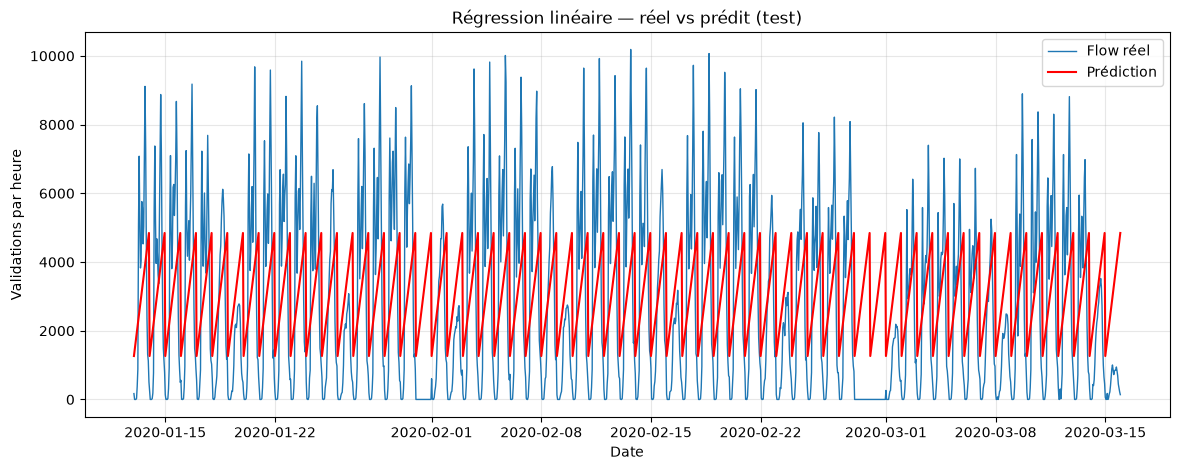

In [4]:
y_pred = model.predict(x_test)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test.index, y_test, label='Flow réel', lw=1)
ax.plot(y_test.index, y_pred, label='Prédiction', lw=1.5, color='red')
ax.set_xlabel('Date')
ax.set_ylabel('Validations par heure')
ax.set_title('Régression linéaire — réel vs prédit (test)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Multiple linear regression

In [5]:
df

,Flow,jour_semaine,type_jour,debut_semaine,heure,heure_semaine
2019-11-01 00:00:00,361,4,Lundi–vendredi,2019-10-28,0,96
2019-11-01 01:00:00,0,4,Lundi–vendredi,2019-10-28,1,97
2019-11-01 02:00:00,0,4,Lundi–vendredi,2019-10-28,2,98
2019-11-01 03:00:00,0,4,Lundi–vendredi,2019-10-28,3,99
2019-11-01 04:00:00,0,4,Lundi–vendredi,2019-10-28,4,100
...,...,...,...,...,...,...
2020-03-15 19:00:00,690,6,Dimanche,2020-03-09,19,163
2020-03-15 20:00:00,445,6,Dimanche,2020-03-09,20,164
2020-03-15 21:00:00,335,6,Dimanche,2020-03-09,21,165
2020-03-15 22:00:00,223,6,Dimanche,2020-03-09,22,166


In [6]:
#On identifie les features et la target pertinente pour notre modèle.
target   = 'Flow'
features = ['heure', 'jour_semaine', 'heure_semaine']   # debut_semaine retiré : c'est du texte, la régression ne peut pas l'utiliser

# Training set (données HORAIRES : df_h)
x_train, x_test = df[features].loc[:'2019-12-16'], df[features].loc['2020-01-13':]
y_train, y_test = df[target].loc[:'2019-12-16'], df[target].loc['2020-01-13':]

print(x_train.shape, y_train.shape)
x_train


(1104, 3) (1104,)


,heure,jour_semaine,heure_semaine
2019-11-01 00:00:00,0,4,96
2019-11-01 01:00:00,1,4,97
2019-11-01 02:00:00,2,4,98
2019-11-01 03:00:00,3,4,99
2019-11-01 04:00:00,4,4,100
...,...,...,...
2019-12-16 19:00:00,19,0,19
2019-12-16 20:00:00,20,0,20
2019-12-16 21:00:00,21,0,21
2019-12-16 22:00:00,22,0,22


In [7]:
model = LinearRegression() 
model.fit(x_train, y_train) 
y_pred = model.predict(x_test) 

print(model.intercept_, model.coef_, )

# STEP 4 - Compare results from the model y_pred with y_test from our test set
s_validation = pd.Series({
    'R²': r2_score(y_test, y_pred),
    'MSE': mean_squared_error(y_test, y_pred),
    'MAE': mean_absolute_error(y_test, y_pred),
})
s_validation

2214.2746280586784 [168.32043551  -7.5386197  -12.60643741]


R²     1.883228e-01
MSE    5.667985e+06
MAE    1.998326e+03
dtype: float64

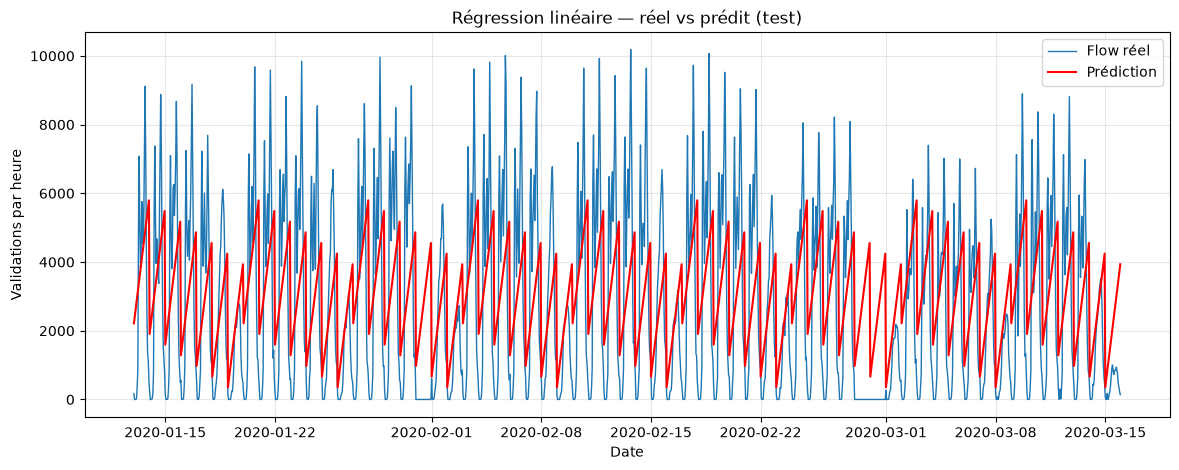

In [8]:
y_pred = model.predict(x_test)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test.index, y_test, label='Flow réel', lw=1)
ax.plot(y_test.index, y_pred, label='Prédiction', lw=1.5, color='red')
ax.set_xlabel('Date')
ax.set_ylabel('Validations par heure')
ax.set_title('Régression linéaire — réel vs prédit (test)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()